# ♿ CitizenTech · Acessibilidade Urbana ♿

## 🌐 Global Solution 2026.2 · FIAP 🌐
## 💻 Engenharia de Software · IA & Machine Learning 💻

### 👥 Integrantes
| Nome | RM |
|---|---|
| André Luiz Fernandes de Queiroz | 554503 |
| Marcos Vinicius da Silva Costa | 555490 |
| Paulo Poças | 556080 |
| Rafael Bocchi | 557603 |
| Rafael Federici de Oliveira | 554736 |

# 📋 Sobre o Projeto

Este notebook contem:

1. Problema e dados reais
2. Escolha do modelo
3. Preparação e divisão treino/teste
4. Treino com diferentes hiperparâmetros
5. Resultados em treino e teste
6. Conclusão

**Pergunta de ML**

> Dadas as características de uma escola e os demais itens de acessibilidade que ela declara, qual a probabilidade de **faltar rampa de acesso**?

Como usamos a base **nacional completa de 2025/2026**, também comparamos o problema e o desempenho do modelo **entre as regiões do Brasil**.

## 1. Problema e dados reais

### Fonte dos dados
| Item | Descrição |
|---|---|
| Fonte | INEP - Censo Escolar da Educação Básica (microdados) |
| Link | https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/microdados/censo-escolar |
| Período | Censo Escolar **2025/2026** (coluna `NU_ANO_CENSO`) |
| Arquivo usado | `acessibilidade_escola_2025-2026.csv` (nacional, 214.192 escolas, 290 colunas) |
| Recorte | **Brasil inteiro** (27 UFs, 5 regiões), Escolas em atividade: 180.540 |
| Natureza | Dados reais, públicos e **autodeclarados** pelas escolas. Sem dados pessoais (sem CNPJ e nome da escola). |

In [ ]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, ConfusionMatrixDisplay)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42                      # reprodutibilidade
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
Path("figuras").mkdir(exist_ok=True)
Path("saidas").mkdir(exist_ok=True)

df = pd.read_csv("dados/escolas_brasil_2025.csv.gz", sep=";", low_memory=False)   # o pandas descomprime o .gz
print("Escolas no Brasil (arquivo completo):", df.shape[0], "| colunas:", df.shape[1])
print("UFs:", df["SG_UF"].nunique(), "| regiões:", df["NO_REGIAO"].nunique())
print("Ano do Censo:", df["NU_ANO_CENSO"].unique())
df["TP_SITUACAO_FUNCIONAMENTO"].value_counts().rename("escolas").to_frame()

Escolas no Brasil (arquivo completo): 214192 | colunas: 287
UFs: 27 | regiões: 5
Ano do Censo: [2025]


,escolas
TP_SITUACAO_FUNCIONAMENTO,
1,180540
2,29780
3,3872


`TP_SITUACAO_FUNCIONAMENTO`:

1 = em atividade;

2 = paralisada;

3 = extinta no ano do Censo

> Códigos do dicionário de dados do INEP. Escolas paralisadas ou extintas não entram na amostra, então **ficamos só com as em atividade**.

Escolas em atividade no Brasil: 180540

Valores ausentes no alvo: 0
y_sem_rampa
tem rampa    62.0 %
SEM rampa    38.0 %
Name: proportion, dtype: str


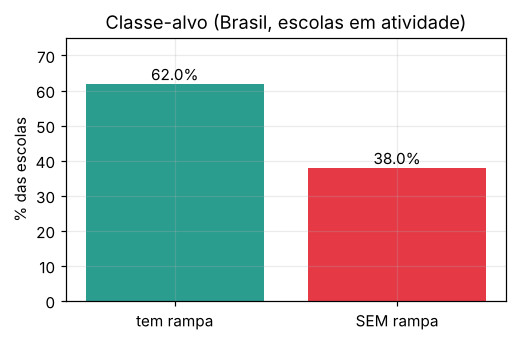

In [ ]:
esc = df[df["TP_SITUACAO_FUNCIONAMENTO"] == 1].copy()
print("Escolas em atividade no Brasil:", len(esc))

# --- Variável-alvo ---
# IN_ACESSIBILIDADE_RAMPAS: 1 = escola declara ter rampas; 0 = não declara.
# Alvo (classe positiva) é a BARREIRA: 1 = FALTA rampa.
esc["y_sem_rampa"] = (esc["IN_ACESSIBILIDADE_RAMPAS"] == 0).astype(int)

print("\nValores ausentes no alvo:", esc["IN_ACESSIBILIDADE_RAMPAS"].isna().sum())
prop = esc["y_sem_rampa"].value_counts(normalize=True).rename({0: "tem rampa", 1: "SEM rampa"})
print((prop * 100).round(1).astype(str) + " %")

fig, ax = plt.subplots(figsize=(4.8, 3.2))
ax.bar(prop.index, prop.values * 100, color=["#2a9d8f", "#e63946"])
ax.set_ylabel("% das escolas"); ax.set_title("Classe-alvo (Brasil, escolas em atividade)")
for i, v in enumerate(prop.values * 100): ax.text(i, v + 1, f"{v:.1f}%", ha="center")
ax.set_ylim(0, 75); plt.tight_layout(); plt.savefig("figuras/01_classe_alvo.png"); plt.show()

A classe-alvo é **moderadamente desbalanceada** (~38% sem rampa contra ~62% com rampa). Um modelo que sempre dissesse "tem rampa" acertaria ~62%, então **a acurácia sozinha engana**: usaremos AUC, precisão, recall e F1, e a divisão treino/teste será **estratificada**. O desbalanceamento é leve, então não usamos reamostragem.

### 1.1 O problema por Região, UF, Rede e Zona

Brasil: 180540 escolas | sem rampa: 38.0%



,escolas,pct_sem_rampa
NO_REGIAO,,
Norte,22207,55.1
Nordeste,59988,34.4
Centro-Oeste,10653,22.4
Sudeste,61420,42.6
Sul,26271,27.5


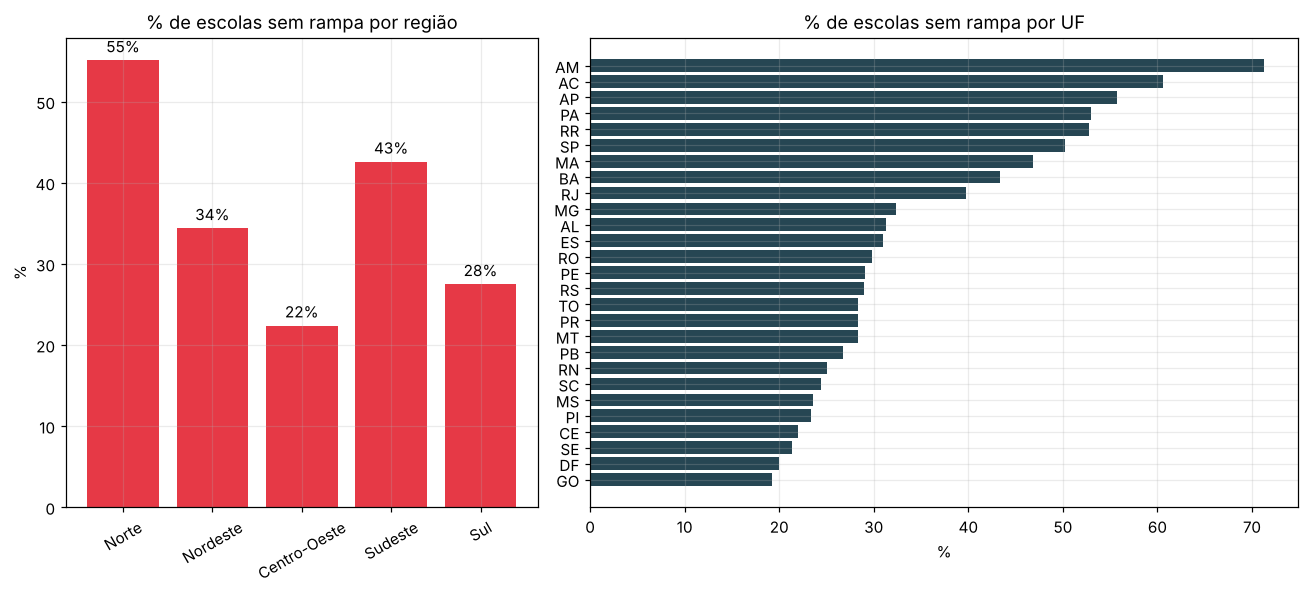

In [ ]:
REGIOES = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
por_reg = (esc.groupby("NO_REGIAO")["y_sem_rampa"].agg(escolas="size", pct_sem_rampa="mean")
             .reindex(REGIOES))
por_reg["pct_sem_rampa"] = (por_reg["pct_sem_rampa"] * 100).round(1)
por_uf = (esc.groupby("SG_UF")["y_sem_rampa"].agg(escolas="size", pct_sem_rampa="mean")
            .sort_values("pct_sem_rampa"))
por_uf["pct_sem_rampa"] = (por_uf["pct_sem_rampa"] * 100).round(1)
print(f"Brasil: {len(esc)} escolas | sem rampa: {esc['y_sem_rampa'].mean()*100:.1f}%\n")
display(por_reg)

fig, axs = plt.subplots(1, 2, figsize=(12, 5.5), gridspec_kw={"width_ratios": [1, 1.5]})
axs[0].bar(por_reg.index, por_reg["pct_sem_rampa"], color="#e63946")
axs[0].set_title("% de escolas sem rampa por região"); axs[0].set_ylabel("%"); axs[0].tick_params(axis="x", rotation=30)
for i, v in enumerate(por_reg["pct_sem_rampa"]): axs[0].text(i, v + 1, f"{v:.0f}%", ha="center")
axs[1].barh(por_uf.index, por_uf["pct_sem_rampa"], color="#264653")
axs[1].set_title("% de escolas sem rampa por UF"); axs[1].set_xlabel("%")
plt.tight_layout(); plt.savefig("figuras/01b_sem_rampa_regiao_uf.png"); plt.show()

In [ ]:
dep = {1: "Federal", 2: "Estadual", 3: "Municipal", 4: "Privada"}
loc = {1: "Urbana", 2: "Rural"}
esc["rede"] = esc["TP_DEPENDENCIA"].map(dep)

por_dep = esc.groupby("rede")["y_sem_rampa"].agg(escolas="size", pct_sem_rampa="mean")
por_dep["pct_sem_rampa"] = (por_dep["pct_sem_rampa"] * 100).round(1)
por_loc = esc.assign(zona=esc["TP_LOCALIZACAO"].map(loc)).groupby("zona")["y_sem_rampa"].agg(escolas="size", pct_sem_rampa="mean")
por_loc["pct_sem_rampa"] = (por_loc["pct_sem_rampa"] * 100).round(1)
display(por_dep); display(por_loc)

cruz = (esc.pivot_table(index="NO_REGIAO", columns="rede", values="y_sem_rampa", aggfunc="mean") * 100).round(1).reindex(REGIOES)
print("% sem rampa por região x rede:")
display(cruz)

,escolas,pct_sem_rampa
rede,,
Estadual,29998,32.7
Federal,716,10.2
Municipal,107372,41.1
Privada,42454,34.4


,escolas,pct_sem_rampa
zona,,
Rural,50763,53.7
Urbana,129777,31.9


% sem rampa por região x rede:


rede,Estadual,Federal,Municipal,Privada
NO_REGIAO,,,,
Norte,43.9,4.8,61.9,22.4
Nordeste,26.4,6.8,38.1,25.2
Centro-Oeste,16.3,4.3,29.2,15.9
Sudeste,40.9,13.0,41.4,45.6
Sul,24.2,19.3,29.9,25.4


**Leitura:** a falta de rampa **não é igual no país**: é bem maior no Norte e menor no Centro-Oeste e no Sul. A zona **rural** também concentra mais escolas sem rampa. Parte da diferença regional pode vir da composição da rede (por exemplo, proporção de escolas municipais e privadas), por isso o modelo usa as características de cada escola, e depois checamos o desempenho por região.

## 2. Escolha do modelo

| Modelos | Serve ao problema? |
|---|---|
| **XGBoost** | ✅ **Escolhido.** Dados **tabulares** com ~200 variáveis binárias e contagens; aprende interações (ex.: "escola estadual + banheiro adaptado + sem elevador"); lida com valores ausentes nativamente |
| Random Forest | Boa alternativa, mas tende a exigir mais árvores/profundidade para o mesmo desempenho. |
| MLP | Redes neurais tendem a render menos que árvores em dados tabulares pequenos e são mais difíceis de explicar. |
| LSTM | ❌ Para **séries temporais**. Não temos sequência temporal. |
| KMeans + PCA | ❌ É **não supervisionado**; nossa pergunta tem um rótulo (falta ou não de rampa). |

## 3. Preparação dos dados e divisão treino/teste

### 3.1 Vazamento de dados

A coluna `IN_ACESSIBILIDADE_INEXISTENTE` significa "a escola declara **nenhum** recurso de acessibilidade". Se ela vale 1, então rampa é, por definição, 0. Usá-la como entrada daria a resposta ao modelo. Verificamos:

In [ ]:
display(pd.crosstab(esc["IN_ACESSIBILIDADE_INEXISTENTE"], esc["IN_ACESSIBILIDADE_RAMPAS"],
                    rownames=["Acessibilidade INEXISTENTE"], colnames=["Tem rampa"]))
print("-> Quando INEXISTENTE = 1, NUNCA há rampa. Essa coluna vaza o alvo e será REMOVIDA.")

Tem rampa,0.0,1.0
Acessibilidade INEXISTENTE,,
0.0,29863,111887
1.0,38790,0


-> Quando INEXISTENTE = 1, NUNCA há rampa. Essa coluna vaza o alvo e será REMOVIDA.


### 3.2 Códigos especiais
Várias colunas `QT_*` (quantidades) usam o valor **88888** como "não informado". Tratá-lo como número distorceria médias e resutados. Vamos convertê-lo em **ausente (NaN)**.

In [ ]:
qt_cols = [c for c in esc.columns if c.startswith("QT_")]
n88 = {c: int((esc[c] == 88888).sum()) for c in qt_cols if (esc[c] == 88888).any()}
print(f"{len(n88)} colunas QT_ continham o código 88888. Exemplos:", dict(list(n88.items())[:5]))

26 colunas QT_ continham o código 88888. Exemplos: {'QT_EQUIP_DVD': 74, 'QT_EQUIP_SOM': 902, 'QT_EQUIP_TV': 1893, 'QT_EQUIP_LOUSA_DIGITAL': 58, 'QT_EQUIP_MULTIMIDIA': 1091}


### 3.3 Colunas que entram como variáveis de entrada
Removemos: identificadores e nomes (`NO_*`, `CO_*`, `SG_*`), datas (`DT_*`), CNPJ (`NU_*`), colunas de vínculo/parceria/mantenedora de preenchimento esparso, o **alvo** e o **vazamento**. Depois removemos colunas **constantes** ou com **mais de 50% de ausentes**.

In [ ]:
PREFIXOS_FORA = ("NO_", "CO_", "DT_", "NU_", "SG_", "IN_FORMA_CONT", "IN_MANT", "IN_VINCULO",
                 "TP_PODER", "IN_RESERVA", "IN_LOCAL_FUNC_SOCIO", "IN_LOCAL_FUNC_UNID",
                 "IN_LOCAL_FUNC_PRISIONAL", "TP_INDIGENA")
COLUNAS_FORA = {"IN_ACESSIBILIDADE_RAMPAS",          # alvo
                "IN_ACESSIBILIDADE_INEXISTENTE",     # vazamento do alvo
                "TP_SITUACAO_FUNCIONAMENTO",         # constante após o filtro
                "TP_REGULAMENTACAO", "TP_RESPONSAVEL_REGULAMENTACAO", "TP_CATEGORIA_ESCOLA_PRIVADA",
                "y_sem_rampa", "rede"}

candidatas = [c for c in esc.columns if not c.startswith(PREFIXOS_FORA) and c not in COLUNAS_FORA]
X_all = esc[candidatas].copy()

# 88888 -> NaN nas colunas de quantidade
for c in X_all.columns:
    if c.startswith("QT_"):
        X_all.loc[X_all[c] == 88888, c] = np.nan

# remove constantes e colunas com > 50% de ausentes
pct_nulo = X_all.isna().mean()
constantes = [c for c in X_all.columns if X_all[c].nunique(dropna=True) <= 1]
muito_nulo = pct_nulo[pct_nulo > 0.5].index.tolist()
remover = sorted(set(constantes) | set(muito_nulo))
X = X_all.drop(columns=remover)
X = X.astype("float32")          # menos memória e treino mais rápido
y = esc["y_sem_rampa"]

print(f"Candidatas: {len(candidatas)} | removidas (constantes/>50% ausentes): {len(remover)} {remover}")
print(f"Variáveis de entrada finais: {X.shape[1]} | amostras: {X.shape[0]}")
print(f"Valores ausentes restantes: {X.isna().sum().sum()} ({X.isna().mean().mean()*100:.2f}% das células)")

Candidatas: 215 | removidas (constantes/>50% ausentes): 1 ['TP_OCUPACAO_GALPAO']
Variáveis de entrada finais: 214 | amostras: 180540
Valores ausentes restantes: 24673 (0.06% das células)


In [ ]:
ACESS_OUTROS = [c for c in X.columns if c.startswith("IN_ACESSIBILIDADE")] + [
    "IN_BANHEIRO_PNE", "QT_SALAS_UTILIZADAS_ACESSIVEIS", "IN_SALA_ATENDIMENTO_ESPECIAL", "TP_AEE",
    "IN_MATERIAL_PED_EDU_ESP", "IN_MATERIAL_PED_BIL_SURDOS", "QT_PROF_TRAD_LIBRAS",
    "QT_PROF_REVISOR_BRAILLE", "IN_ESPECIAL_EXCLUSIVA"]
ACESS_OUTROS = [c for c in ACESS_OUTROS if c in X.columns]
PERFIL = [c for c in X.columns if c not in ACESS_OUTROS]
print(f"Grupo 'perfil/estrutura': {len(PERFIL)} variáveis")
print(f"Grupo 'outros itens de acessibilidade': {len(ACESS_OUTROS)} variáveis ->")
print(ACESS_OUTROS)

Grupo 'perfil/estrutura': 197 variáveis
Grupo 'outros itens de acessibilidade': 17 variáveis ->
['IN_ACESSIBILIDADE_CORRIMAO', 'IN_ACESSIBILIDADE_ELEVADOR', 'IN_ACESSIBILIDADE_PISOS_TATEIS', 'IN_ACESSIBILIDADE_VAO_LIVRE', 'IN_ACESSIBILIDADE_SINAL_SONORO', 'IN_ACESSIBILIDADE_SINAL_TATIL', 'IN_ACESSIBILIDADE_SINAL_VISUAL', 'IN_ACESSIBILIDADE_SINALIZACAO', 'IN_BANHEIRO_PNE', 'QT_SALAS_UTILIZADAS_ACESSIVEIS', 'IN_SALA_ATENDIMENTO_ESPECIAL', 'TP_AEE', 'IN_MATERIAL_PED_EDU_ESP', 'IN_MATERIAL_PED_BIL_SURDOS', 'QT_PROF_TRAD_LIBRAS', 'QT_PROF_REVISOR_BRAILLE', 'IN_ESPECIAL_EXCLUSIVA']


### 3.4 Divisão treino/teste

In [ ]:
estrato = esc["CO_REGIAO"].astype(str) + "_" + y.astype(str)      # região + alvo
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, stratify=estrato, random_state=SEED)
print(f"Treino: {X_tr.shape[0]} escolas ({y_tr.mean()*100:.1f}% sem rampa)")
print(f"Teste : {X_te.shape[0]} escolas ({y_te.mean()*100:.1f}% sem rampa)")

def avaliar(modelo, Xa, ya, limiar=0.5):
    p = modelo.predict_proba(Xa)[:, 1]
    pred = (p >= limiar).astype(int)
    return {"Acurácia": accuracy_score(ya, pred), "Precisão": precision_score(ya, pred),
            "Recall": recall_score(ya, pred), "F1": f1_score(ya, pred), "AUC": roc_auc_score(ya, p)}

# Referências (não são o modelo final)
dummy = DummyClassifier(strategy="prior").fit(X_tr, y_tr)
logreg = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                       LogisticRegression(max_iter=1000, random_state=SEED)).fit(X_tr, y_tr)
ref = pd.DataFrame({"Sempre a classe majoritária": {**avaliar(dummy, X_te, y_te)},
                    "Regressão logística (teste)": {**avaliar(logreg, X_te, y_te)}}).T.round(3)
ref

Treino: 144432 escolas (38.0% sem rampa)
Teste : 36108 escolas (38.0% sem rampa)


,Acurácia,Precisão,Recall,F1,AUC
Sempre a classe majoritária,0.620,0.000,0.000,0.000,0.500
Regressão logística (teste),0.767,0.717,0.638,0.675,0.822


## 4. Treino com diferentes hiperparâmetros

Escolhemos **3 hiperparâmetros** do XGBoost, que controlam a complexidade do modelo e, portanto, o risco de *overfitting*:

| Hiperparâmetro | O que controla |
|---|---|
| `max_depth` | profundidade de cada árvore (mais profunda = decora mais) |
| `learning_rate` | tamanho do passo de cada árvore (menor = aprende mais devagar e mais estável) |
| `n_estimators` | quantidade de árvores |

Testamos **12 combinações**, indo de modelos simples a modelos propositalmente complexos para **enxergar o overfitting**. Cada combinação é avaliada por **validação cruzada estratificada de 5 partições, somente no treino**, com a métrica **AUC**.

In [ ]:
COMBINACOES = [  # (max_depth, learning_rate, n_estimators)
    (2, 0.05, 100), (3, 0.05, 200), (3, 0.10, 100), (4, 0.10, 200),
    (4, 0.05, 400), (6, 0.10, 200), (6, 0.05, 300), (8, 0.10, 200),
    (8, 0.20, 300), (10, 0.10, 300), (10, 0.30, 300), (12, 0.30, 500)]
grade = [dict(max_depth=[d], learning_rate=[lr], n_estimators=[n]) for d, lr, n in COMBINACOES]

busca = GridSearchCV(
    estimator=XGBClassifier(tree_method="hist", random_state=SEED, n_jobs=1, eval_metric="logloss"),
    param_grid=grade,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),   # CV só no TREINO
    scoring="roc_auc", return_train_score=True, n_jobs=-1, refit=True)

t0 = time.time()
busca.fit(X_tr, y_tr)
print(f"{len(COMBINACOES)} combinações x 5 partições = {len(COMBINACOES)*5} treinos em {time.time()-t0:.0f}s")
print("Melhor combinação:", busca.best_params_)

res = pd.DataFrame(busca.cv_results_)
tabela = pd.DataFrame({
    "max_depth": res["param_max_depth"].astype(int),
    "learning_rate": res["param_learning_rate"].astype(float),
    "n_estimators": res["param_n_estimators"].astype(int),
    "AUC treino (média CV)": res["mean_train_score"],
    "AUC validação (média CV)": res["mean_test_score"],
    "desvio validação": res["std_test_score"]})
tabela["gap (treino - validação)"] = tabela["AUC treino (média CV)"] - tabela["AUC validação (média CV)"]
tabela = tabela.round(4)
tabela.to_csv("saidas/busca_hiperparametros.csv", index=False)
tabela

12 combinações x 5 partições = 60 treinos em 1101s
Melhor combinação: {'learning_rate': 0.1, 'max_depth': 8, 'n_estimators': 200}


,max_depth,learning_rate,n_estimators,AUC treino (média CV),AUC validação (média CV),desvio validação,gap (treino - validação)
0,2,0.05,100,0.8208,0.8203,0.0020,0.0006
1,3,0.05,200,0.8344,0.8319,0.0022,0.0025
2,3,0.10,100,0.8343,0.8319,0.0020,0.0024
3,4,0.10,200,0.8504,0.8399,0.0018,0.0104
4,4,0.05,400,0.8502,0.8399,0.0019,0.0103
5,6,0.10,200,0.8780,0.8442,0.0021,0.0338
6,6,0.05,300,0.8711,0.8440,0.0019,0.0270
7,8,0.10,200,0.9211,0.8459,0.0023,0.0752
8,8,0.20,300,0.9714,0.8403,0.0025,0.1312
9,10,0.10,300,0.9809,0.8446,0.0021,0.1363


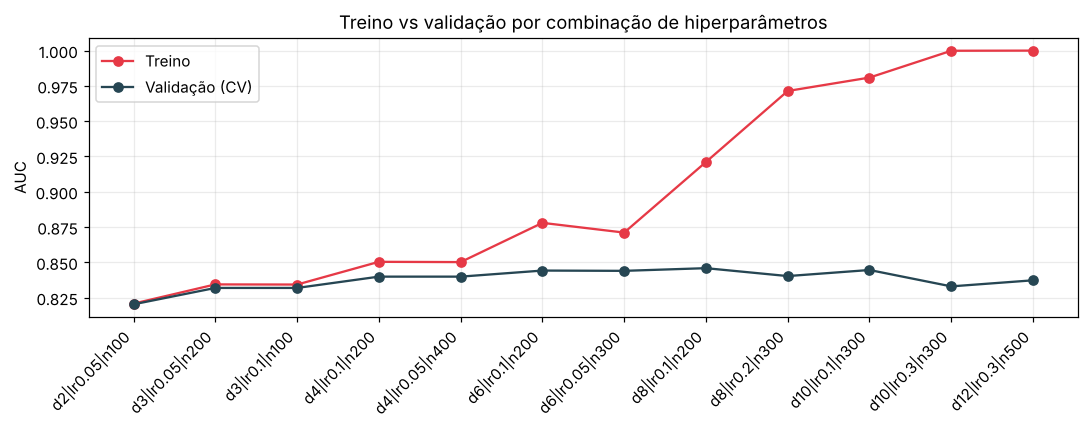

In [ ]:
rot = [f"d{d}|lr{lr}|n{n}" for d, lr, n in COMBINACOES]
x = np.arange(len(rot))
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x, tabela["AUC treino (média CV)"], "o-", color="#e63946", label="Treino")
ax.plot(x, tabela["AUC validação (média CV)"], "o-", color="#264653", label="Validação (CV)")
ax.set_xticks(x); ax.set_xticklabels(rot, rotation=45, ha="right")
ax.set_ylabel("AUC"); ax.set_title("Treino vs validação por combinação de hiperparâmetros")
ax.legend(); plt.tight_layout(); plt.savefig("figuras/02_treino_vs_validacao.png"); plt.show()

**Leitura:** conforme a complexidade cresce, o AUC de **treino** sobe até ~1,0 (o modelo decora o treino), mas o AUC de **validação** não melhora e até cai. É o *overfitting* clássico. A melhor combinação é a que maximiza a **validação**, e não o treino.

## 5. Resultados em treino e teste

In [ ]:
best = busca.best_estimator_
m_tr = avaliar(best, X_tr, y_tr)
m_te = avaliar(best, X_te, y_te)
cv_auc = busca.best_score_

comparacao = pd.DataFrame({"Treino": m_tr, "Teste": m_te})
comparacao["Diferença (treino - teste)"] = comparacao["Treino"] - comparacao["Teste"]
display(comparacao.round(3))
print(f"AUC médio na validação cruzada (só treino): {cv_auc:.3f}  ->  AUC no teste: {m_te['AUC']:.3f}")

todas = pd.concat([ref.rename(index={"Regressão logística (teste)": "Regressão logística"}),
                   pd.DataFrame({"XGBoost (teste)": m_te}).T.round(3)])
print("\nComparação no conjunto de TESTE:")
display(todas)

,Treino,Teste,Diferença (treino - teste)
Acurácia,0.831,0.787,0.045
Precisão,0.814,0.755,0.059
Recall,0.721,0.650,0.072
F1,0.765,0.698,0.066
AUC,0.914,0.850,0.064


AUC médio na validação cruzada (só treino): 0.846  ->  AUC no teste: 0.850

Comparação no conjunto de TESTE:


,Acurácia,Precisão,Recall,F1,AUC
Sempre a classe majoritária,0.620,0.000,0.000,0.000,0.500
Regressão logística,0.767,0.717,0.638,0.675,0.822
XGBoost (teste),0.787,0.755,0.650,0.698,0.850


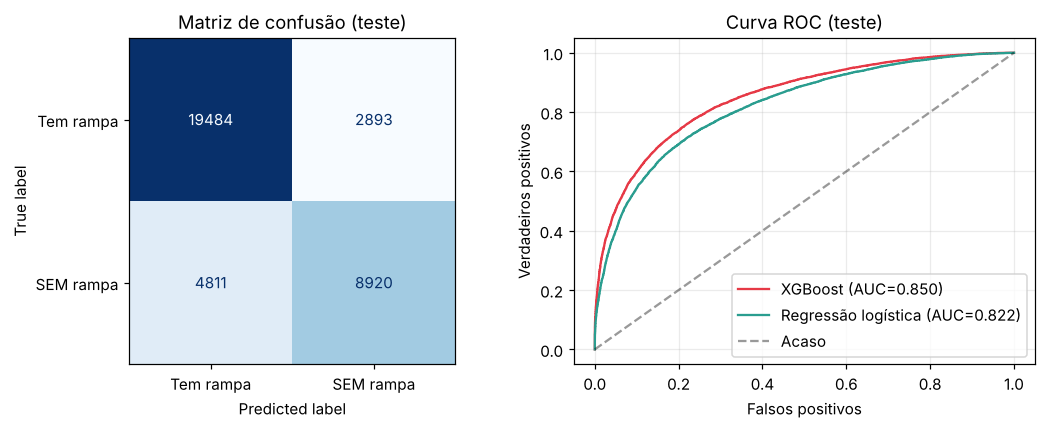

Teste: 8920 acertos ao apontar 'sem rampa' | 2893 alarmes falsos | 4811 barreiras não detectadas | 19484 acertos em 'tem rampa'


In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
p_te = best.predict_proba(X_te)[:, 1]
pred_te = (p_te >= 0.5).astype(int)

ConfusionMatrixDisplay(confusion_matrix(y_te, pred_te), display_labels=["Tem rampa", "SEM rampa"]).plot(
    ax=axs[0], cmap="Blues", colorbar=False, values_format="d")
axs[0].set_title("Matriz de confusão (teste)"); axs[0].grid(False)

for nome, mdl, cor in [("XGBoost", best, "#e63946"), ("Regressão logística", logreg, "#2a9d8f")]:
    fpr, tpr, _ = roc_curve(y_te, mdl.predict_proba(X_te)[:, 1])
    axs[1].plot(fpr, tpr, color=cor, label=f"{nome} (AUC={roc_auc_score(y_te, mdl.predict_proba(X_te)[:,1]):.3f})")
axs[1].plot([0, 1], [0, 1], "k--", alpha=.4, label="Acaso")
axs[1].set_xlabel("Falsos positivos"); axs[1].set_ylabel("Verdadeiros positivos"); axs[1].set_title("Curva ROC (teste)")
axs[1].legend(); plt.tight_layout(); plt.savefig("figuras/03_confusao_roc.png"); plt.show()

tn, fp, fn, tp = confusion_matrix(y_te, pred_te).ravel()
print(f"Teste: {tp} acertos ao apontar 'sem rampa' | {fp} alarmes falsos | {fn} barreiras não detectadas | {tn} acertos em 'tem rampa'")

### 5.1 O modelo por região
O modelo foi treinado com o país inteiro. Avaliamos o **conjunto de teste separado por região** (a divisão foi estratificada por região, então todas estão bem representadas).

,Escolas (teste),% real sem rampa,Acurácia,Precisão,Recall,F1,AUC
Região,,,,,,,
Norte,4441,55.145,0.823,0.841,0.837,0.839,0.900
Nordeste,11998,34.364,0.791,0.709,0.666,0.686,0.846
Centro-Oeste,2131,22.384,0.828,0.706,0.398,0.509,0.832
Sudeste,12284,42.616,0.764,0.766,0.641,0.698,0.836
Sul,5254,27.541,0.782,0.678,0.400,0.503,0.800


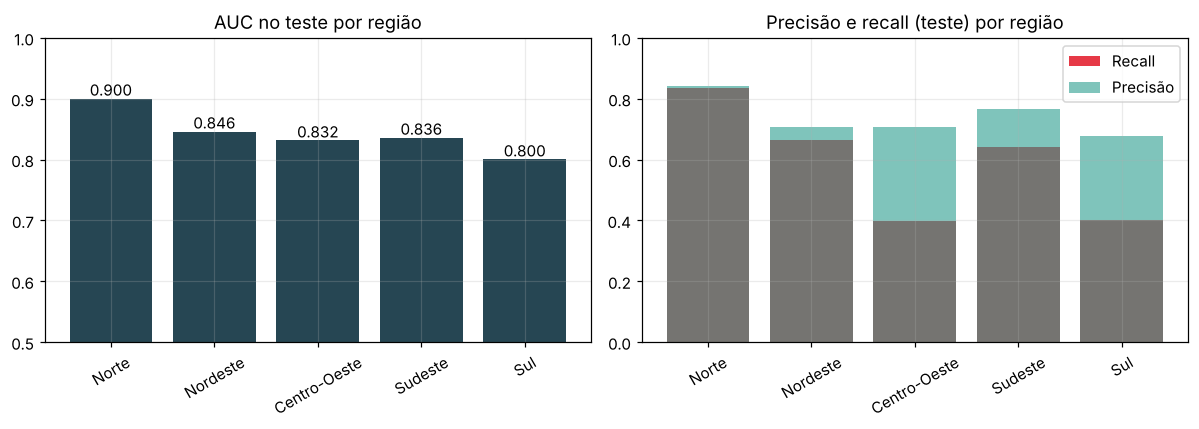

In [ ]:
reg_te = esc.loc[X_te.index, "NO_REGIAO"]
linhas = []
for r in REGIOES:
    m = (reg_te == r).values
    linhas.append({"Região": r, "Escolas (teste)": int(m.sum()), "% real sem rampa": y_te[m].mean() * 100,
                   **avaliar(best, X_te[m], y_te[m])})
por_regiao = pd.DataFrame(linhas).set_index("Região")
display(por_regiao.round(3))

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].bar(por_regiao.index, por_regiao["AUC"], color="#264653"); axs[0].set_ylim(0.5, 1.0)
axs[0].set_title("AUC no teste por região"); axs[0].tick_params(axis="x", rotation=30)
for i, v in enumerate(por_regiao["AUC"]): axs[0].text(i, v + 0.005, f"{v:.3f}", ha="center")
axs[1].bar(por_regiao.index, por_regiao["Recall"], color="#e63946", label="Recall")
axs[1].bar(por_regiao.index, por_regiao["Precisão"], color="#2a9d8f", alpha=.6, label="Precisão")
axs[1].set_ylim(0, 1); axs[1].set_title("Precisão e recall (teste) por região"); axs[1].legend(); axs[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("figuras/03b_desempenho_por_regiao.png"); plt.show()

In [ ]:
linhas035 = []
for r in REGIOES:
    m = (reg_te == r).values
    met = avaliar(best, X_te[m], y_te[m], limiar=0.35)
    linhas035.append({"Região": r, "Precisão (limiar 0,35)": met["Precisão"],
                      "Recall (limiar 0,35)": met["Recall"], "F1 (limiar 0,35)": met["F1"]})
comp_limiar = pd.DataFrame(linhas035).set_index("Região")
comp_limiar.insert(0, "Recall (limiar 0,50)", por_regiao["Recall"])
comp_limiar.insert(0, "% real sem rampa", por_regiao["% real sem rampa"])
display(comp_limiar.round(3))

,% real sem rampa,"Recall (limiar 0,50)","Precisão (limiar 0,35)","Recall (limiar 0,35)","F1 (limiar 0,35)"
Região,,,,,
Norte,55.145,0.837,0.792,0.891,0.838
Nordeste,34.364,0.666,0.632,0.782,0.699
Centro-Oeste,22.384,0.398,0.565,0.589,0.577
Sudeste,42.616,0.641,0.677,0.778,0.724
Sul,27.541,0.400,0.582,0.586,0.584


### 5.2 Faixas de risco
Calculamos uma **probabilidade** para uma faixa de risco. Dividimos os estabelecimentos do **teste** em faixas e comparamos com a realidade.

In [ ]:
faixas = pd.cut(p_te, bins=[0, 0.35, 0.65, 1.0], labels=["Baixa (<35%)", "Média (35–65%)", "Alta (>=65%)"], include_lowest=True)
risco = (pd.DataFrame({"faixa": faixas, "real_sem_rampa": y_te.values})
           .groupby("faixa", observed=True)["real_sem_rampa"].agg(escolas="size", pct_real_sem_rampa="mean"))
risco["pct_real_sem_rampa"] = (risco["pct_real_sem_rampa"] * 100).round(1)
risco

,escolas,pct_real_sem_rampa
faixa,,
Baixa (<35%),20276,15.4
Média (35–65%),7433,48.6
Alta (>=65%),8399,83.3


## 6. Conclusão

## 6. Conclusão

### O que o resultado significa

1. Com 214 características simples (197 de perfil e estrutura da escola e 17 de outros itens de acessibilidade), o XGBoost separa escolas com e sem rampa com **AUC de 0,85** no teste, bem acima do acaso (0,50). A regressão logística simples chega a 0,82, ou seja, ela já capta boa parte do sinal, e o XGBoost acrescenta um ganho **moderado** (+0,03 de AUC; F1 de 0,70 contra 0,68).
2. Quando o modelo aponta "sem rampa", ele **acerta 76% das vezes** (precisão) e **encontra 65% das escolas que realmente não têm rampa** (recall). No teste foram 8.920 acertos ao apontar "sem rampa", 2.893 alarmes falsos e 4.811 barreiras que passariam despercebidas (de 13.731).
3. **A probabilidade permite priorizar.** Na faixa de risco **Alta** (≥ 65%), 83% das escolas realmente não têm rampa, contra 49% na faixa **Média** e 15% na faixa **Baixa** (< 35%). Os estabelecimentos da faixa Alta são os que devem ter mais atenção.
4. **O problema não é igual no país.** A falta de rampa vai de **22,4% no Centro-Oeste a 55,1% no Norte**, e chega a 53,7% na zona rural contra 31,9% na urbana (também varia por rede: 41,1% nas municipais e 10,2% nas federais). O AUC do modelo fica entre 0,80 (Sul) e 0,90 (Norte): ele **ordena bem as escolas por risco em todas as regiões**.
5. **Um corte único de 50% não funciona igual em todas as regiões.** O recall é de 0,84 no Norte, mas de apenas ~0,40 no Centro-Oeste e no Sul, onde a barreira é mais rara (22% e 28% das escolas). Baixando o limiar para 0,35, o recall nessas duas regiões sobe para ~0,59, ao custo de mais alarmes falsos. Por isso a plataforma deve usar **probabilidade e faixas de risco**, e não um sim/não único para o país inteiro.

### Integração com a API (C#)
As previsões de todas as 180.540 escolas em atividade foram exportadas para `saidas/previsoes_escolas_oof.csv` (101.155 na faixa Baixa, 37.388 na Média e 41.997 na Alta), obtidas por validação cruzada para que cada escola receba a probabilidade de um modelo que **não a viu** no treino. A API importa esse arquivo e informa o risco no diagnóstico.

### ODS conectados
**ODS 4:** educação de qualidade, inclusiva e equitativa

**ODS 10:** redução das desigualdades

**ODS 11:** cidades e comunidades sustentáveis, com acesso a espaços seguros e acessíveis

## 7. Saídas para a integração com a API (C#)

A disciplina de C# usa estes arquivos para alimentar a API:
- `saidas/previsoes_escolas_oof.csv`: probabilidade de **faltar rampa** para cada escola em atividade do **Brasil** (com região e UF, para a API poder filtrar). Usamos previsões **out-of-fold** (validação cruzada com os melhores hiperparâmetros): cada escola recebe uma probabilidade de um modelo que **não a viu** no treino, evitando previsões otimistas.
- `saidas/modelo_xgb_sem_rampa.json`: o modelo treinado (formato nativo do XGBoost).
- `saidas/metricas.json`: métricas finais.

In [ ]:
cv_final = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
modelo_cv = XGBClassifier(tree_method="hist", random_state=SEED, n_jobs=1, eval_metric="logloss", **busca.best_params_)
p_oof = cross_val_predict(modelo_cv, X, y, cv=cv_final, method="predict_proba")[:, 1]

saida = pd.DataFrame({
    "co_entidade": esc["CO_ENTIDADE"].values,
    "regiao": esc["NO_REGIAO"].values,
    "sg_uf": esc["SG_UF"].values,
    "co_municipio": esc["CO_MUNICIPIO"].values,
    "tp_dependencia": esc["TP_DEPENDENCIA"].values,
    "prob_sem_rampa": p_oof.round(4),
    "sem_rampa_declarado": y.values})
saida["faixa_risco"] = pd.cut(saida["prob_sem_rampa"], bins=[0, 0.35, 0.65, 1.0],
                              labels=["BAIXA", "MEDIA", "ALTA"], include_lowest=True)
saida.to_csv("saidas/previsoes_escolas_oof.csv", index=False)
best.save_model("saidas/modelo_xgb_sem_rampa.json")

metricas = {"fonte": "INEP Censo Escolar 2025 (Brasil, escolas em atividade)", "n_amostras": int(len(X)),
            "n_variaveis": int(X.shape[1]), "modelo": "XGBClassifier",
            "melhores_hiperparametros": {k: (int(v) if k != "learning_rate" else float(v)) for k, v in busca.best_params_.items()},
            "auc_validacao_cruzada_treino": round(float(cv_auc), 4),
            "treino": {k: round(float(v), 4) for k, v in m_tr.items()},
            "teste": {k: round(float(v), 4) for k, v in m_te.items()},
            "teste_por_regiao": json.loads(por_regiao.round(4).to_json(orient="index"))}
Path("saidas/metricas.json").write_text(json.dumps(metricas, indent=2, ensure_ascii=False), encoding="utf-8")

print(saida["faixa_risco"].value_counts().rename("escolas").to_frame().T)
saida.head()

faixa_risco   BAIXA   ALTA  MEDIA
escolas      101155  41997  37388


,co_entidade,regiao,sg_uf,co_municipio,tp_dependencia,prob_sem_rampa,sem_rampa_declarado,faixa_risco
0,11022558,Norte,RO,1100015,2,0.9507,1,ALTA
1,11024275,Norte,RO,1100015,2,0.0164,0,BAIXA
2,11024666,Norte,RO,1100015,3,0.2790,0,BAIXA
3,11024682,Norte,RO,1100015,2,0.0039,0,BAIXA
4,11024917,Norte,RO,1100015,3,0.6380,0,MEDIA
